In [ ]:
!pip install -q datasets pandas numpy matplotlib seaborn scikit-learn pyarrow gradio huggingface_hub joblib

##Load Data & Ground Truth Labels


In [ ]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from huggingface_hub import hf_hub_download

# 1. Load NASA Telemanom dataset (Channel P-1)
dataset = load_dataset("appleparan/telemanom", name="P-1")
train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)

# 2. Download ground truth anomaly labels
labels_path = hf_hub_download(
    repo_id="appleparan/telemanom",
    filename="labeled_anomalies.csv",
    repo_type="dataset"
)
labels_df = pd.read_csv(labels_path)

# 3. Filter labels for channel P-1 and create binary target column
p1_labels = labels_df[labels_df["chan_id"] == "P-1"].iloc[0]
anomaly_intervals = ast.literal_eval(p1_labels["anomaly_sequences"])
print("P-1 Anomaly Sequences:", anomaly_intervals)

y_test = np.zeros(len(test_df), dtype=int)
for start, end in anomaly_intervals:
    y_test[start : end + 1] = 1

test_df["is_anomaly"] = y_test
print("\nClass Distribution in Testing Data:")
print(test_df["is_anomaly"].value_counts())

Training Shape: (2872, 26)
Testing Shape: (8505, 26)
P-1 Anomaly Sequences: [[2149, 2349], [4536, 4844], [3539, 3779]]

Class Distribution in Testing Data:
is_anomaly
0    7754
1     751
Name: count, dtype: int64


##Exploratory Data Analysis (EDA) Visualization

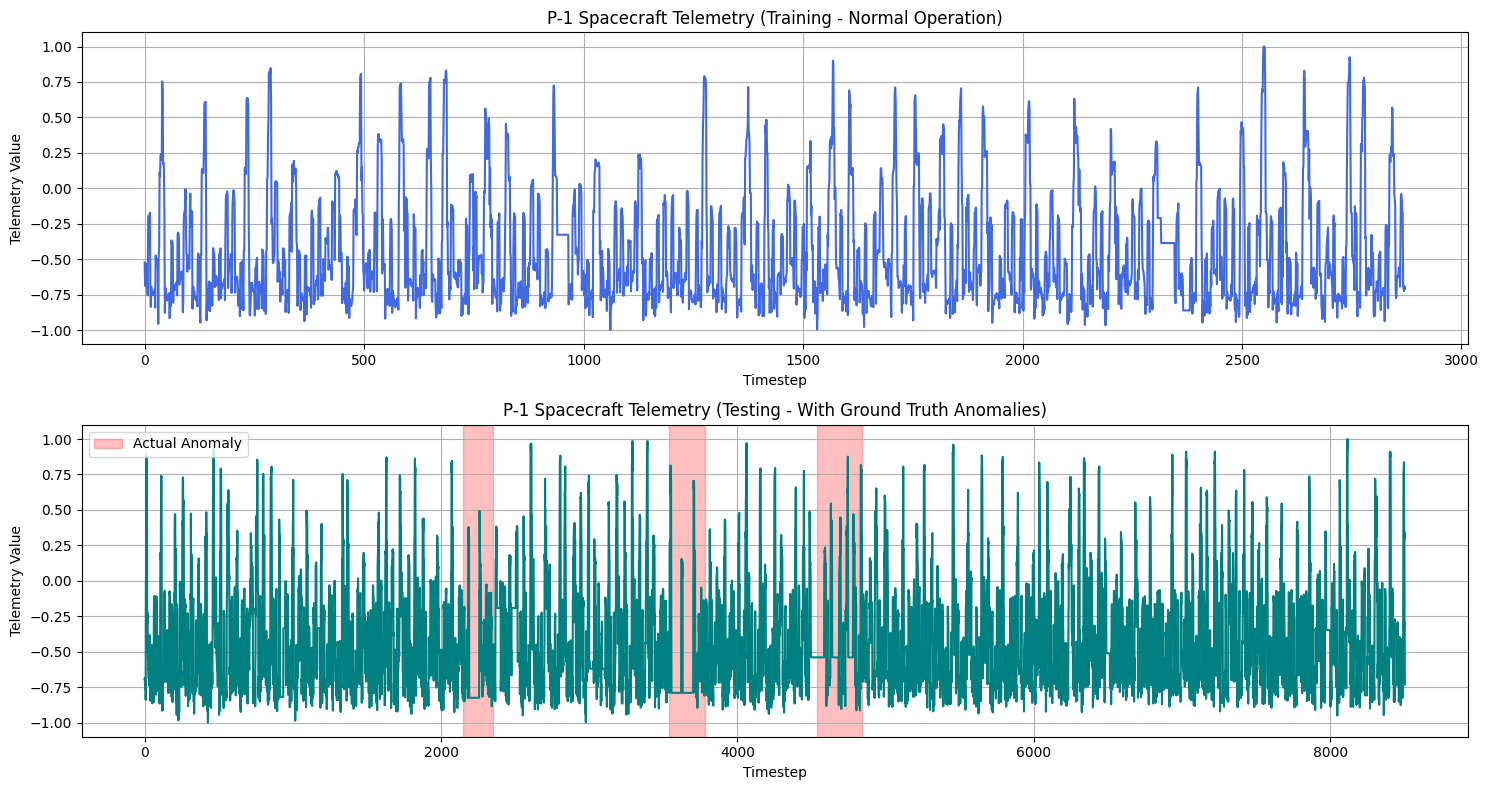

In [ ]:
# Plot Training and Testing Telemetry Signals
fig, axes = plt.subplots(2, 1, figsize=(15, 8))

axes[0].plot(train_df["timestep"], train_df["value"], color="royalblue")
axes[0].set_title("P-1 Spacecraft Telemetry (Training - Normal Operation)")
axes[0].set_xlabel("Timestep")
axes[0].set_ylabel("Telemetry Value")
axes[0].grid(True)

axes[1].plot(test_df["timestep"], test_df["value"], color="teal")
for i, (start, end) in enumerate(anomaly_intervals):
    axes[1].axvspan(start, end, color="red", alpha=0.25, label="Actual Anomaly" if i == 0 else "")
axes[1].set_title("P-1 Spacecraft Telemetry (Testing - With Ground Truth Anomalies)")
axes[1].set_xlabel("Timestep")
axes[1].set_ylabel("Telemetry Value")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

##Feature Selection & Feature Engineering

In [ ]:
from sklearn.preprocessing import StandardScaler

# 1. Drop constant columns (nunique <= 1) and 'timestep'
constant_cols = [col for col in train_df.columns if train_df[col].nunique() <= 1]
cols_to_drop = constant_cols + ["timestep"]

X_train = train_df.drop(columns=cols_to_drop)
X_test = test_df.drop(columns=cols_to_drop + ["is_anomaly"])

print(f"Dropped {len(constant_cols)} constant columns: {constant_cols}")

# 2. Extract temporal rolling features to capture flatlines and spikes
def extract_features(df):
    feat = df.copy()
    feat["rolling_mean_15"] = feat["value"].rolling(window=15, min_periods=1).mean()
    feat["rolling_std_15"] = feat["value"].rolling(window=15, min_periods=1).std().fillna(0)
    feat["value_diff"] = feat["value"].diff().abs().fillna(0)
    return feat

X_train_feat = extract_features(X_train)
X_test_feat = extract_features(X_test)

# 3. Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled = scaler.transform(X_test_feat)

print("Processed Training Shape:", X_train_scaled.shape)
print("Processed Testing Shape:", X_test_scaled.shape)

Dropped 9 constant columns: ['cmd_3', 'cmd_7', 'cmd_9', 'cmd_11', 'cmd_14', 'cmd_15', 'cmd_19', 'cmd_22', 'cmd_23']
Processed Training Shape: (2872, 19)
Processed Testing Shape: (8505, 19)


##Model Training, Comparison & Saving Best Model

In [ ]:
import joblib
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import precision_score, recall_score, f1_score

# Estimate contamination rate from test labels
contamination_rate = float(y_test.mean())

# 1. Initialize anomaly detection models
models = {
    "Isolation Forest": IsolationForest(n_estimators=200, contamination=contamination_rate, random_state=42),
    "Local Outlier Factor": LocalOutlierFactor(n_neighbors=30, novelty=True, contamination=contamination_rate),
    "One-Class SVM": OneClassSVM(kernel="rbf", gamma="auto", nu=contamination_rate)
}

results = []
trained_models = {}
predictions = {}

# 2. Train and evaluate each model
for name, model in models.items():
    model.fit(X_train_scaled)
    trained_models[name] = model

    raw_preds = model.predict(X_test_scaled)
    preds = np.where(raw_preds == -1, 1, 0)
    predictions[name] = preds

    results.append({
        "Model": name,
        "Precision": round(precision_score(y_test, preds, zero_division=0), 4),
        "Recall": round(recall_score(y_test, preds, zero_division=0), 4),
        "F1-Score": round(f1_score(y_test, preds, zero_division=0), 4)
    })

# 3. Display comparison table
results_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False)
display(results_df)

# 4. Save the best model
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_preds = predictions[best_model_name]

joblib.dump({
    "model": best_model,
    "scaler": scaler,
    "dropped_cols": cols_to_drop
}, "spaceguard_model.pkl")

print(f"\nBest model ({best_model_name}) saved to 'spaceguard_model.pkl'.")

,Model,Precision,Recall,F1-Score
2,One-Class SVM,0.2443,0.3156,0.2754
1,Local Outlier Factor,0.1781,0.2277,0.1999
0,Isolation Forest,0.0936,0.1012,0.0972



Best model (One-Class SVM) saved to 'spaceguard_model.pkl'.


##Final Detection Visualization

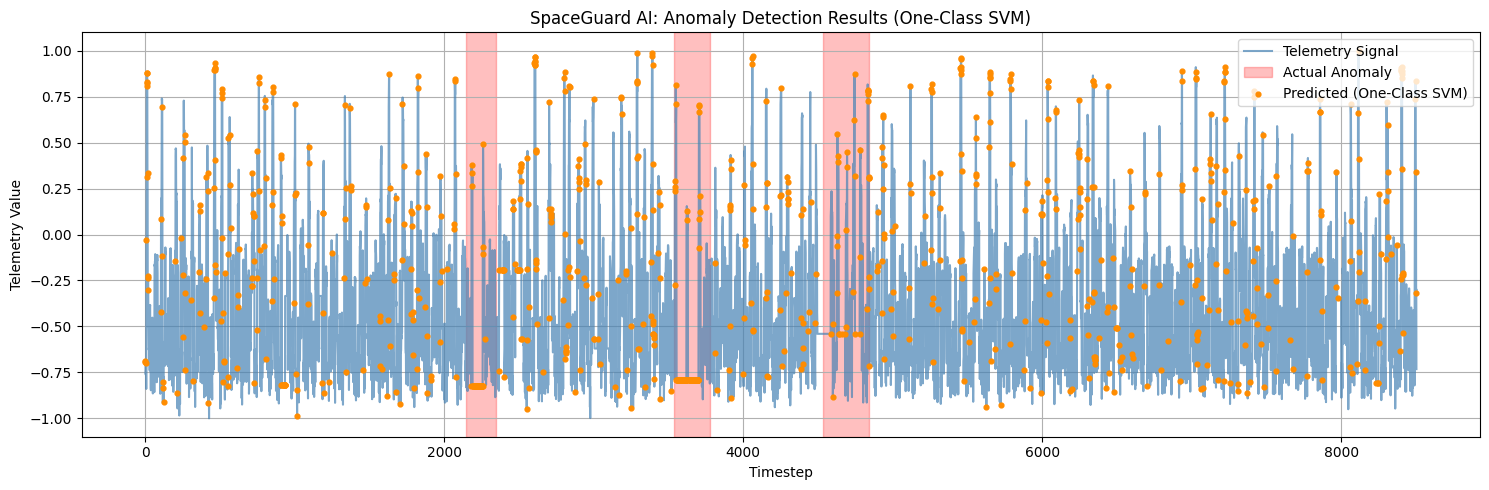

In [ ]:
# Plot model predictions against actual anomaly intervals
plt.figure(figsize=(15, 5))
plt.plot(test_df["timestep"], test_df["value"], label="Telemetry Signal", color="steelblue", alpha=0.7)

for i, (start, end) in enumerate(anomaly_intervals):
    plt.axvspan(start, end, color="red", alpha=0.25, label="Actual Anomaly" if i == 0 else "")

anom_idx = np.where(best_preds == 1)[0]
plt.scatter(
    test_df["timestep"].iloc[anom_idx],
    test_df["value"].iloc[anom_idx],
    color="darkorange",
    s=12,
    label=f"Predicted ({best_model_name})",
    zorder=5
)

plt.title(f"SpaceGuard AI: Anomaly Detection Results ({best_model_name})")
plt.xlabel("Timestep")
plt.ylabel("Telemetry Value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

##Launch Interactive App & Generate App Link

In [ ]:
import gradio as gr

# Load saved model artifacts
artifact = joblib.load("spaceguard_model.pkl")
loaded_model = artifact["model"]
loaded_scaler = artifact["scaler"]
dropped_cols = artifact["dropped_cols"]

def analyze_telemetry(sample_range):
    start_idx, end_idx = map(int, sample_range.split("-"))
    sub_df = test_df.iloc[start_idx:end_idx].copy()

    X_sub = sub_df.drop(columns=[c for c in dropped_cols + ["is_anomaly"] if c in sub_df.columns])
    X_sub_feat = extract_features(X_sub)
    X_sub_scaled = loaded_scaler.transform(X_sub_feat)

    preds = np.where(loaded_model.predict(X_sub_scaled) == -1, 1, 0)
    anomaly_count = int(preds.sum())
    status = "CRITICAL: Anomaly Detected!" if anomaly_count > 10 else "NORMAL: Spacecraft Telemetry Healthy"

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(sub_df["timestep"], sub_df["value"], color="steelblue", label="Telemetry Value")
    anom_points = sub_df[preds == 1]
    ax.scatter(anom_points["timestep"], anom_points["value"], color="red", s=20, label="Detected Anomaly", zorder=5)
    ax.set_title(f"SpaceGuard AI Live Monitor (Timesteps {start_idx} to {end_idx})")
    ax.set_xlabel("Timestep")
    ax.set_ylabel("Telemetry Value")
    ax.legend()
    ax.grid(True)
    plt.tight_layout()

    report = (
        f"System Status: {status}\n"
        f"Total Readings Analyzed: {len(sub_df)}\n"
        f"Anomalous Timesteps Detected: {anomaly_count} ({anomaly_count / len(sub_df) * 100:.2f}%)"
    )
    return report, fig

demo = gr.Interface(
    fn=analyze_telemetry,
    inputs=gr.Dropdown(
        choices=["0-1000", "2000-2500", "3400-4000", "4400-5000", "6000-7000"],
        value="2000-2500",
        label="Select Spacecraft Telemetry Window (Timesteps)"
    ),
    outputs=[
        gr.Textbox(label="Diagnostic Report"),
        gr.Plot(label="Telemetry Anomaly Visualization")
    ],
    title="SpaceGuard AI - Spacecraft Telemetry Anomaly Detector",
    description="Real-time anomaly detection system trained on NASA Telemanom (Channel P-1) dataset."
)

# Launch app and print public URL
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://70e615c284216928ec.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
